# 사전 준비

In [1]:
import warnings
warnings.filterwarnings('ignore')
import re, os, json
from textwrap import dedent
from pprint import pprint

In [2]:
from langchain_community.document_loaders import TextLoader
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.document_loaders import JSONLoader
from langchain_core.documents import Document
from langchain_text_splitters import CharacterTextSplitter
from langchain_text_splitters import RecursiveCharacterTextSplitter
from transformers import AutoTokenizer
from langchain_openai import OpenAIEmbeddings
from langchain_huggingface.embeddings import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_core.prompts import PromptTemplate
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser

In [3]:
from dotenv import load_dotenv
load_dotenv()

True

# 추론-행동 기반 ReAct 에이전트

ReAct는 `추론(REasoning)`과 `행동(ACTing)`을 결합한 방식으로 LLM이 단순히 텍스트를 생성하는 것을 넘어서 환경과 상호 작용하며 복잡한 작업을 수행한다.  
AI가 질문을 받으면 `추론(생각) => 도구 도출 => 결과 관찰 => 다시 추론` 과정을 정답을 얻을 때까지 반복한다.

<img src="./ReAct.png" width="1200" align="left" />

# ReAct 에이전트 준비하기 - Tool, ToolNode 설정

## @tool 데코레이터로 도구를 정의한다.

메뉴 검색을 위한 기존 벡터저장소를 불러와서 검색하는 사용자 정의 도구를 만든다.

`from langchain_chroma import Chroma`

In [4]:
from langchain_ollama import OllamaEmbeddings
from langchain_core.tools import tool
from typing import List
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from langchain_community.tools import TavilySearchResults
from langgraph.graph import START, END, StateGraph, MessagesState
from IPython.display import Image, display

C:\miniconda3\envs\AI_LangGraph\Lib\site-packages\langgraph\checkpoint\base\__init__.py:18: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


벡터저장소를 만들 때 사용했던 임베딩 모델을 불러온 후 벡터저장소를 불러온다.

In [5]:
# 임베딩 모델을 불러온다.
embeddings_model = OllamaEmbeddings(model='bge-m3')

# 벡터저장소를 불러온다.
menu_db = Chroma(
    embedding_function=embeddings_model,
    collection_name='restaurant_menu',
    persist_directory='./chroma_db'
)
print(menu_db._collection.count())

10


@tool 데코레이터를 사용해서 도구를 정의한다.  
@tool 데코레이터는 일반 파이썬 함수를 LangChain의 에이전트가 필요할 때 스스로 판단해서 사용할 수 있는 도구로 만들어준다.

벡터저장소에서 질문과 유사한 메뉴 정보를 찾아오는 도구

In [6]:
@tool
# 검색어를 문자열로 입력받아 벡터저장소에서 검색한 결과를 저장한 List를 리턴시키는 함수
def search_menu(query: str) -> List[str]:
    # @tool 데코레이터를 사용해서 도구로 만드는 함수의 첫 줄에는 반드시 LLM에게 이 도구가 어떤 역할을 하는지 설명하는 docstring을 넣어줘야 한다.
    '''벡터저장소의 레스토랑 메뉴에서 메뉴 정보를 검색합니다.'''
    # 사용자의 질문과 가장 의미적으로 유사한 데이터를 벡터저장소에서 검색한다.
    docs = menu_db.similarity_search(query=query, k=2)
    # 검색한 각 문서(Document 객체)의 본문 내용(page_content)을 하나의 문자열로 만들어서 리스트에 저장한다.
    formatted_docs = '\n\n'.join([doc.page_content for doc in docs])
    # 검색된 문서를 리턴시킨다.
    if len(docs) > 0:
        return formatted_docs
    return '벡터저장소에서 메뉴 정보를 찾을 수 없습니다.'

AI가 자신의 학습 데이터에 없는 최신 정보나 외부 지식을 Tavily 검색 API를 통해 인터넷에서 실시간으로 검색해 올 수 있는 도구

In [7]:
@tool
# 검색어를 문자열로 입력받아 인터넷에서 검색한 결과를 저장한 List를 리턴시키는 함수
def search_web(query: str) -> List[str]:
    '''벡터저장소에 존재하지 않는 정보 또는 외부 지식 정보를 인터넷에서 검색합니다.'''
    # Tavily 검색기 객체를 선언하고 실행한다.
    tavily_search = TavilySearchResults(max_results=2)
    docs = tavily_search.invoke(query)
    # 검색한 각 문서(딕셔너리)의 본문 내용(content)을 하나의 문자열로 만들어서 리스트에 저장한다.
    formatted_docs = '\n\n'.join([doc['content'] for doc in docs])
    # 검색된 문서를 리턴시킨다.
    if len(docs) > 0:
        return formatted_docs
    return '인터넷에서 관련 정보를 찾을 수 없습니다.'

## 도구를 AI 모델에 결합하고 호출 여부를 확인한다.

`from langchain_openai import ChatOpenAI`

LLM 모델을 선언하고 도구를 결합(Binding)한다.

In [8]:
# LLM 모델을 선언한다.
# streaming 속성을 True로 지정하면 답변을 한 번 다 만들어서 줄 때까지 기다리는 것이 아니라, 실시간으로 생성되는 글자(토큰) 단위로 끊어서 즉시 받아볼 수 있게
# 만드는 스트리밍 기능으로 실시간으로 타자를 치는 듯한 효과를 낼 때 사용한다.
llm = ChatOpenAI(model='gpt-4o-mini', streaming=True)

# LLM 모델에 결합할 도구 목록을 만든다.
tools = [search_menu, search_web]

# LLM 모델에 도구를 결합한다.
llm_with_tools = llm.bind_tools(tools=tools)

도구가 결합된 LLM 모델에 질문을 던져서 어떤 도구를 호출하는가 확인한다.

AI는(gpt-4o-mini) 질문을 읽고 자신이 자체적으로 답변할 수 있다 판단해서 연결된 도구를 사용하지 않고 답변한다.

In [9]:
tool_call = llm_with_tools.invoke([HumanMessage(content='안녕하세요')])
tool_call.tool_calls

[]

AI는(gpt-4o-mini) 질문을 읽고 자신이 가진 지식으로는 스테이크 가격을 알 수 없다 판단해서 자신에게 연결된 search_menu 도구를 사용한다고 결정한다.

In [10]:
tool_call = llm_with_tools.invoke([HumanMessage(content='스테이크 메뉴의 가격은 얼마인가요?')])
tool_call.tool_calls

[{'name': 'search_menu',
  'args': {'query': '스테이크'},
  'id': 'call_eMEFiUDUzF7wqiayF0OWFrmo',
  'type': 'tool_call'}]

AI는(gpt-4o-mini) 질문을 읽고 자신이 가진 지식으로는 LangGraph는 무엇인가 알 수 없다 판단해서 자신에게 연결된 search_web도구를 사용한다고 결정한다.

In [11]:
tool_call = llm_with_tools.invoke([HumanMessage(content='LangGraph는 무엇인가요?')])
tool_call.tool_calls

[{'name': 'search_web',
  'args': {'query': 'LangGraph'},
  'id': 'call_a9AoAeIgC2TQRal0I2XBOOIC',
  'type': 'tool_call'}]

In [12]:
tool_call = llm_with_tools.invoke([HumanMessage(content='스테이크 가격은 얼마인가요? 그리고 경기도 성남시의 스테이크 맛집을 알려주세요.')])
tool_call.tool_calls

[{'name': 'search_menu',
  'args': {'query': '스테이크 가격'},
  'id': 'call_wZ3JSUMyvOlkcpmwdEjl2cFz',
  'type': 'tool_call'},
 {'name': 'search_web',
  'args': {'query': '경기도 성남시 스테이크 맛집'},
  'id': 'call_V7uvFuv8vIZOsXQkV64SAefM',
  'type': 'tool_call'}]

In [13]:
tool_call

AIMessage(content='', additional_kwargs={'tool_calls': [{'index': 0, 'id': 'call_wZ3JSUMyvOlkcpmwdEjl2cFz', 'function': {'arguments': '{"query": "스테이크 가격"}', 'name': 'search_menu'}, 'type': 'function'}, {'index': 1, 'id': 'call_V7uvFuv8vIZOsXQkV64SAefM', 'function': {'arguments': '{"query": "경기도 성남시 스테이크 맛집"}', 'name': 'search_web'}, 'type': 'function'}]}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_f1b0ec5777', 'service_tier': 'default'}, id='run--01a1574c-763e-7a83-85be-a6c320ce893c-0', tool_calls=[{'name': 'search_menu', 'args': {'query': '스테이크 가격'}, 'id': 'call_wZ3JSUMyvOlkcpmwdEjl2cFz', 'type': 'tool_call'}, {'name': 'search_web', 'args': {'query': '경기도 성남시 스테이크 맛집'}, 'id': 'call_V7uvFuv8vIZOsXQkV64SAefM', 'type': 'tool_call'}], usage_metadata={'input_tokens': 115, 'output_tokens': 56, 'total_tokens': 171, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0

## 도구 노드(Tool Node)를 만든다.

AI 모델이 요청한 도구 호출을 실행하는 역할을 처리한다.  
가장 최근의 AIMessage에서 도구 호출 요청(tool_calls)을 추출해서 요청된 도구들을 병렬로 실행한 후 각 도구 호출에 대한 결과를 ToolMessage 객체로 리턴한다.

`ToolNode`는 LangGraph 내부에 포함된 사전 제작 라이브러리이다.  
LLM이 외부 도구를 사용할 수 있도록 연결하고 실행하는 과정을 간편하게 처리하기 위해 ToolNode를 import 한다.

In [14]:
from langgraph.prebuilt import ToolNode

도구 노드를 정의한다.

In [15]:
# LangGraph에서 사용할 도구 목록을 만든다.
tools = [search_menu, search_web]

# ToolNode 클래스의 생성자로 LangGraph에서 사용할 도구 목록을 넘겨서 도구 노드를 만든다.
tool_node = ToolNode(tools=tools)
tool_node

tools(tags=None, recurse=True, explode_args=False, func_accepts_config=True, func_accepts={'store': ('__pregel_store', None)}, tools_by_name={'search_menu': StructuredTool(name='search_menu', description='벡터저장소의 레스토랑 메뉴에서 메뉴 정보를 검색합니다.', args_schema=<class 'langchain_core.utils.pydantic.search_menu'>, func=<function search_menu at 0x00000179B376B9C0>), 'search_web': StructuredTool(name='search_web', description='벡터저장소에 존재하지 않는 정보 또는 외부 지식 정보를 인터넷에서 검색합니다.', args_schema=<class 'langchain_core.utils.pydantic.search_web'>, func=<function search_web at 0x00000179B38971A0>)}, tool_to_state_args={'search_menu': {}, 'search_web': {}}, tool_to_store_arg={'search_menu': None, 'search_web': None}, handle_tool_errors=True, messages_key='messages')

## LangGraph에서 도구 노드 실행 테스트

그래프 객체를 생성한다.

In [16]:
builder = StateGraph(MessagesState)

도구 노드를 추가한다.

In [17]:
builder.add_node('tool_node', tool_node)

엣지를 추가한다.

In [18]:
builder.add_edge(START, 'tool_node')
builder.add_edge('tool_node', END)

# set_entry_point() 메소드의 인수로 노드를 넘겨주면 그래프가 실행될 때 무조건 넘겨준 노드 부터 시작하라는 진입점을 지정한다.
# builder.set_entry_point('tool_node')

그래프를 컴파일한다.

In [19]:
graph = builder.compile()

그래프를 시각화한다.

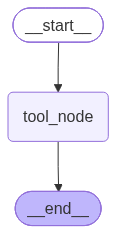

In [20]:
display(Image(graph.get_graph().draw_mermaid_png()))

그래프를 실행한다.

In [21]:
tool_call = llm_with_tools.invoke([HumanMessage(content='스테이크 메뉴의 가격은 얼마인가요?')])
tool_call

AIMessage(content='', additional_kwargs={'tool_calls': [{'index': 0, 'id': 'call_j8QLUKCeCrlOk8GyNCoERja4', 'function': {'arguments': '{"query":"스테이크"}', 'name': 'search_menu'}, 'type': 'function'}]}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_f1b0ec5777', 'service_tier': 'default'}, id='run--01a1574c-cc74-7b63-99f5-0f50e25e2211-0', tool_calls=[{'name': 'search_menu', 'args': {'query': '스테이크'}, 'id': 'call_j8QLUKCeCrlOk8GyNCoERja4', 'type': 'tool_call'}], usage_metadata={'input_tokens': 101, 'output_tokens': 16, 'total_tokens': 117, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

invoke() 메소드를 실행할 때 넘겨주는 딕셔너리의 key를 'messages'로 한 이유는 StateGraph를 이용해서 LangGraph 객체를 만들 때 MessagesState를 넘겼고 MessagesState를 이용해서 상태를 만들면 'messages'라는 key가 자동으로 생성되기 때문이다.

In [22]:
results = graph.invoke({'messages': [tool_call]})

for result in results['messages']:
    print(result.content)
    print('-' * 100)


----------------------------------------------------------------------------------------------------
1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.
----------------------------------------------------------------------------------------------------


In [23]:
results = graph.invoke({'messages': [llm_with_tools.invoke([HumanMessage(content='스테이크 메뉴의 가격은 얼마인가요?')])]})

for result in results['messages']:
    print(result.content)
    print('-' * 100)


----------------------------------------------------------------------------------------------------
1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.
----------------------------------------------------------------------------------------------------


# ReAct 에이전트 구현하기 - LangGraph 내장 함수(create_react_agent) 사용
<br>
<img src="./ReActAgent.png" width="1200" align="left" />

ReAct는 LLM이 문제를 해결할 때 `추론(Reasoning)`과 `행동(Acting)`을 번갈아 수행하도록 유도하는 자율형 AI 에이전트 프롬프트 및 문제 해결 기법이다.

ReAct 패턴은 핵심적으로 3단계의 반복 루프로 작동한다.

<img src="./ReAct2.png" width="800" align="left" />

Thought(추론/생각): 현재 상태를 분석하고, 문제를 해결하기 위해 다음 단계로 무엇을 해야 할지 스스로 계획을 세운다.  
Action(행동/도구 호출): 추론 결과를 바탕으로 외부 도구를 호출하거나 실행 가능한 명령을 내린다.  
Observation(관찰/결과 확인): 행동의 실행 결과로 반환된 정보나 데이터를 확인하고 컨텍스트에 추가한다.

이 3단계 과정을 목표가 달성될 때까지 반복하며, 최종적으로 사용자에게 정확한 답변(Final Answer)을 제공합니다.

복잡한 코드 작성 없에 ReAct 에이전트 그래프를 자동으로 생성하기 위해서 create_react_agent를 import 한다.

In [24]:
from langgraph.prebuilt import create_react_agent

## LangGraph 내장 함수로 ReAct 에이전트 그래프 생성하기

LangGraph 내장 함수 create_react_agent를 이용하면 StateGraph를 정의하고 노드와 엣지를 추가하는 번거로운 과정 실행없이 ReAct 에이전트 그래프를 만들 수 있다.

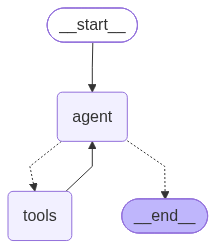

In [25]:
# llm = ChatOpenAI(model='gpt-4o-mini', streaming=True)
# tools = [search_menu, search_web]

# create_react_agent() 함수의 인수로 LLM 모델, 도구 목록, 프롬프트를 넘겨서 ReAct 에이전트 그래프를 만든다.
# LLM 모델, 도구 목록을 설정하면 LLM 모델에 도구를 결합하는 llm.bind_tools(tools=tools) 코드가 자동으로 실행된다.
graph = create_react_agent(
    # ReAct 에이전트가 사용할 LLM 모델을 설정한다.
    model=llm,
    # ReAct 에이전트가 사용할 수 있는 도구 목록을 설정한다.
    tools=tools
)

# ReAct 에이전트 그래프 시각화
display(Image(graph.get_graph().draw_mermaid_png()))

## LangGraph 내장 함수로 생성한 ReAct 에이전트 그래프 실행하기

In [26]:
# ReAct 에이전트에게 전달한 입력 데이터
# LangGraph의 에이전트는 대화 기록을 기반으로 동작하므로 대화 기록을 기억하는 상태의 key는 MessagesState 클래스를 상속받아 상태를 만들면 자동으로 생성되는
# messages 이므로 에이전트에게 전달할 입력 데이터를 만들 때 딕셔너리의 key는 반드시 messages를 사용해야 한다.
# messages key에는 List[AnyMessage] 형태의 데이터를 데이터를 넘겨야 하므로 HumanMessage 객체를 사용해서 질문을 만들어야 한다.
input_ = {'messages': [HumanMessage(content='스테이크 메뉴의 가격은 얼마인가요?')]}

# ReAct 에이전트 실행이 완료되면, 에이전트가 최종적으로 업데이트한 전체 상태 MessagesState 클래스에 의해서 자동으로 생성되는 messages key에 할당한다.
# invoke() 메소드가 실행되면 인수로 지정된 입력 데이터를 바탕으로 ReAct 에이전트가 사용할 도구를 결정한다. AIMessage가 생성된다.
# 도구를 사용하기로 결정되면 도구 노드에서 도구를 실행한다. ToolMessage가 생성된다.
# 도구를 실행했으면 다시 ReAct 에이전트가 도구가 검색한 결과를 사용자가 이해할 수 있는 최종 답변을 완성한다. AIMessage가 생성된다.
# 최종 답변을 완성했으므로 ReAct 에이전트 그래프가 종료되고 누적된 모든 메시지 리스트를 리턴한다.
messages = graph.invoke(input_)

In [27]:
for message in messages['messages']:
    # pretty_print() 메소드는 LangChain이나 LangGraph 환경에서 대화 메시지 객체 클래스인 HumanMessage, AIMessage, ToolMessage, SystemMessage 등에 내장된
    # 출력 전용 메소드이다.
    message.pretty_print()

================================ Human Message =================================

스테이크 메뉴의 가격은 얼마인가요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_7SJxRCgH4cp7R3ZXFeVMkkSG)
 Call ID: call_7SJxRCgH4cp7R3ZXFeVMkkSG
  Args:
    query: 스테이크
================================= Tool Message =================================
Name: search_menu

1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.
================================== Ai Message ==================================

스테이크 메뉴의 가격은 다음과 같습니다:

1. **시그니처 스테이크**: ₩35,000
2. **안심 스테이크 샐러드**: ₩26,000


## 프롬프트를 지정해서 LangGraph 내장 함수로 ReAct 에이전트 그래프 생성하기

프롬프트를 만든다.

프롬프트에 페르소나와 AI가 행동해야 할 규칙을 정의한다.  
단계별 행동은 `질문 이해 => 도구 사용 => 출처 인용 => 정확한 답변 구성 => 최종 답변을 제공`을 강제한다.  
도구를 사용하지 않았거나 출처가 없는 정보는 절대로 제공하지 말 것을 강력하게 경고하여, AI가 거짓말을 지어내는 현상(환각, Hallucination)을 방지한다.

In [28]:
prompt = dedent('''
    당신은 인간의 질문에 답변하도록 설계된 AI 어시스턴트입니다.
    제공된 도구를 활용하여 질문의 주의깊게 이해하고, 필요한 정보를 검색하여 답변을 구성하세요.
    
    질문에 답변하려면 다음 단계를 따르세요.
    1. 질문을 주의 깊게 읽고 이해하세요.
    2. 필요한 정보를 얻기 위해 제공된 도구를 사용하세요.
    3. 도구를 사용할 때는 아래의 형식을 따르세요.
    4. 답변이 완료되었다고 판단되면 최종 답변을 제공하세요.
    
    도구를 사용할 때는 반드시 아래의 형식을 준수해야 합니다.
    Action: 도구 이름
    Action Input: 도구에 입력할 값
    
    예시1:
    Action: search_menu
    Action Input: 스테이크
    
    예시2:
    Action: search_web
    Action Input: AI의 역사
    
    도구 사용이 필요하지 않은 경우 직접 답변할 수 있으나, 답변에 포함되는 모든 사실적 정보에는 반드시 인용 출처가 있어야 합니다.
    인용 출처가 없는 정보와 불필요한 정보는 절대 제공하지 마십시오.
    최종 답변은 사용자의 질문과 직접 관련되도록 명확하고 간결하게 작성하세요.
''')

ReAct 에이전트 그래프를 만든다.

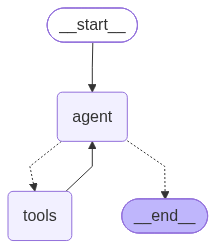

In [29]:
graph = create_react_agent(
    model=llm,
    tools=tools,
    # 위에서 정의한 환각 방지용 프롬프트를 지정하여 AI의 기본 동작 규칙으로 주입한다.
    prompt=prompt
)

display(Image(graph.get_graph().draw_mermaid_png()))

프롬프트를 지정해서 LangGraph 내장 함수로 생성한 ReAct 에이전트 그래프 실행하기

In [30]:
input_ = {'messages': [HumanMessage(content='스테이크 메뉴의 가격은 얼마인가요?')]}
messages = graph.invoke(input_)

In [31]:
for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

스테이크 메뉴의 가격은 얼마인가요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_mvNs8fOxd1MQN4HHYwwOEy66)
 Call ID: call_mvNs8fOxd1MQN4HHYwwOEy66
  Args:
    query: 스테이크
================================= Tool Message =================================
Name: search_menu

1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.
================================== Ai Message ==================================

스테이크 메뉴의 가격은 다음과 같습니다:

1. **시그니처 스테이크**: ₩35,000
   - **주요 식재료**: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스

# ReAct 에이전트 구현하기 - 사용자 정의 조건부 엣지 함수 사용

create_react_agent() 함수를 사용하지 않고 ReAct 에이전트 내부 구조를 직접 커스텀하여 구현한다.
<br>
<img src="./ReActAgent2.png" width="1200" align="left" />

## ReAct 에이전트 조건부 엣지 함수 사용자 정의

조건부 엣지 함수에서 도구 호출 여부에 따라 그래프 종료 여부를 결정하고 도구 실행히 필요한 경우에는 그래프가 종료되지 않고 계속 실행한다.

상태를 정의한다.

In [32]:
# MessagesState 클래스를 상속받았으므로 Message 객체를 messages key가 자동으로 생성된다.
class GraphState(MessagesState):
    pass

In [33]:
GraphState.__annotations__.keys()

dict_keys(['messages'])

ReAct 에이전트 역할을 할 노드(함수)를 정의한다.

LangGraph의 노드 함수는 그래프의 상태를 입력받아 변경된 상태를 딕셔너리로 리턴시킨다.

In [34]:
def react_agent(state: GraphState):
    # create_react_agent() 함수를 사용할 때 prompt 속성에 지정했던 환각 현상 방지 프롬프트를 SystemMessage 객체로 만든다.
    system_message = SystemMessage(content=prompt)
    # SystemMessage 객체에 그래프가 실행될 때 넘어오는 질문인 HumanMessage 객체를 합쳐준다.
    messages = [system_message] + state['messages']
    # LLM이 직접 답변할 수 있지 또는 답변하기 위해 도구를 사용해야 하는지 도구를 사용해야 한다면 어떤 도구를 사용해야 하는지 결정하는 LLM 모델를 만든다.
    # llm = ChatOpenAI(model='gpt-4o-mini', streaming=True)
    # tools = [search_menu, search_web]
    # llm_with_tools = llm.bind_tools(tools=tools)
    response = llm_with_tools.invoke(messages)
    # LLM 모델이 생성한 답변인 AIMessage로 상태를 업데이트 한다.
    return {'messages': [response]}

조건부 엣지 함수를 정의한다.

ReAct 에이전트 역할을 할 노드가 실행된 뒤, 도구를 실행하러 갈지 아니면 이대로 대화를 끝낼지 결정하는 함수

In [35]:
def conditional_edge(state: GraphState):
    # 상태에서 대화 메시지 중 가장 최신(마지막) 메시지를 꺼내온다.
    last_message = state['messages'][-1]
    # 도구 호출이 있으면 도구 실행 노드로 도구 호출이 없으면 답변을 생성하고 그래프를 종료한다.
    # 리스트가 if의 조건부에 사용되면 빈 리스트는 False로 취급되고 빈 리스트가 아니면 True로 취급된다.
    if last_message.tool_calls:
        # ReAct 에이전트가 도구를 사용해야 한다고 판단했다면 도구를 실행하는 노드로 보낸다.
        return 'tools'
    # ReAct 에이전트가 도구를 사용할 필요 없다고 판단했다면 도구 없이 최종 답변을 다 마쳤다는 뜻이므로, 그래프를 완전히 종료하는 END를 리턴한다.
    return END

그래프 객체를 만든다.

In [36]:
builder = StateGraph(GraphState)

그래프 객체에 노드를 추가한다.

In [37]:
builder.add_node('agent', react_agent) # 도구 사용 여부를 판단하는 노드를 추가한다.
builder.add_node('tools', ToolNode(tools=tools)) # 도구를 실제로 실행하는 노드를 추가한다.

그래프 객체에 엣지를 추가한다.

In [38]:
builder.add_edge(START, 'agent')
# 조건부 엣지를 추가한다.
builder.add_conditional_edges(
    # 조건부 엣지가 실행될 노드
    'agent',
    # 실행할 조건부 엣지 함수
    conditional_edge,
    # 조건부 엣지 함수 실행 결과 리턴값에 따라 분기할 노드 목록 딕셔너리
    {
        # 조건부 엣지 함수 실행 결과가 'tools'이면 'tools' 노드로 가고, END면 그래프를 종료하는 END로 엣지를 연결한다.
        'tools': 'tools',
        END: END
    }
)
builder.add_edge('tools', 'agent')

그래프를 컴파일한다.

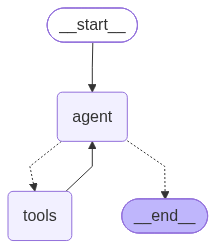

In [39]:
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

그래프를 실행한다.

In [40]:
input_ = {'messages': [HumanMessage(content='스테이크 메뉴의 가격은 얼마인가요?')]}
# 완성된 LangGraph(graph)에 입력값(input_)을 넣어 실행(invoke)하고, 최종적으로 누적이 완료된 결과 상태(state) 데이터를 받아서 messages 변수에 저장한다.
# LangGraph 로직의 작동 순서
# LangGraph가 실행되면 START에서 'agent' 노드로 진입한다.
# 'agent' 노드는 react_agent() 함수를 실행하고 react_agent() 함수로는 HumanMessage가 저장된 상태가 전달된다.
# react_agent() 함수는 prompt를 이용해서 SystemMessage를 만들고 SystemMessage에 HumanMessage를 붙여서 도구 사용 여부를 판단한다.
# react_agent() 함수 search_menu 도구를 사용해야 한다는 AIMessage로 상태를 업데이트 한다.
# 'agent' 노드가 종료되면 conditional_edge() 조건부 엣지 함수가 실행되고 도구 사용 여부에 따라서 분기 방향을 결정한다.
# 도구를 사용해야 한다면 'tools' 노드로 진입해서 도구 노드 실행해서 도구를 실행한 결과 ToolMessage로 상태를 업데이트하고 'agent' 노드로 진입한다.
# 답변이 완성되서 더 이상 도구를 사용할 필요가 없다면 END를 리턴해서 그래프를 종료한다.
messages = graph.invoke(input_)

In [41]:
for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

스테이크 메뉴의 가격은 얼마인가요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_jrlZ0as8JLqTppWq3hNdWfuY)
 Call ID: call_jrlZ0as8JLqTppWq3hNdWfuY
  Args:
    query: 스테이크
================================= Tool Message =================================
Name: search_menu

1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.
================================== Ai Message ==================================

스테이크 메뉴의 가격은 다음과 같습니다:

1. **시그니처 스테이크**: ₩35,000
2. **안심 스테이크 샐러드**: ₩26,000

각 메뉴의 주요 재료와 설

# ReAct 에이전트 구현하기 - tools_condition 조건부 엣지 함수 사용
<br>
<img src="./ReActAgent3.png" width="1200" align="left" />

## tools_condition() 함수의 역할

LangGraph에서 제공하는 ReAct 스타일의 워크플로우를 구축할 때 사용되는 조건부 엣지 함수로 LLM이 도구를 사용해야 할지 아니면 최종 답변을 제공하고 종료해야 할지를 판단하는 역할을 한다.

tools_condition() 함수는 그래프의 상태에서 가장 최근에 생성된(마지막) 메시지를 확인하여 다음과 같은 분기 처리를 실행한다.  
▶ 도구 호출 요청이 있는 경우: tool_calls가 있다.  
&nbsp;&nbsp;&nbsp;LLM이 답변을 위해 도구를 호출해야 한다고 판단하여 tool_calls에 도구 정보가 포함된 경우, `tools`라는 문자열을 리턴해서 `tools` 노드로 간다.  
▶ 도구 호출 요청이 없는 경우: tool_calls가 없다.  
&nbsp;&nbsp;&nbsp;LLM이 도구를 쓸 필요 없이 바로 사용자에게 최종 답변을 줄 수 있다고 판단한 경우, `END`를 리턴해서 그래프를 `종료`한다.

LangGraph가 제공하는 조건부 엣지 함수인 tools_condition을 사용하기 위해 import 한다.

In [42]:
from langgraph.prebuilt import tools_condition

위에서 만들었던 사용자 정의 조건부 엣지 함수 사용했던 상태(GraphState), ReAct 에이전트 역할을 할 노드(react_agent)는 그대로 사용한다.

tools_condition() 함수를 사용자 정의 조건부 엣지 함수와 같은 역할을 하는 그래프를 만든다. tools_condition() 함수가 conditional_edge() 조건부 엣지 함수와 동일한 기능을 실행한다.  
위에서 만들었던 conditional_edge 함수가 자동으로 생성된다.

그래프를 구성한다.

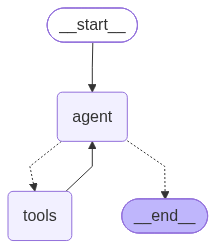

In [43]:
# 그래프 객체를 만든다.
builder = StateGraph(GraphState)

# 그래프 객체에 노드를 추가한다.
builder.add_node('agent', react_agent)
builder.add_node('tools', ToolNode(tools=tools))

# 그래프 객체에 엣지를 추가한다.
builder.add_edge(START, 'agent')
# tools_condition 함수를 사용한 조건부 엣지를 추가한다.
builder.add_conditional_edges(
    'agent',
    # conditional_edge,
    # {
        # 'tools': 'tools',
        # END: END
    # }
    # 위의 주석으로 처리한 부분을 tools_condition 함수로 대체한다.
    # 'agent' 노드가 실행된 후 tools_condition 함수가 실행되며 도구를 사용해야 하면 'tools'를 리턴해서 'tools' 노드를 실행하고 도구를 사용할 필요가 없다면
    # END를 리턴해서 그래프를 종료한다.
    tools_condition
)
builder.add_edge('tools', 'agent')

# 그래프를 컴파일한다.
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [44]:
input_ = {'messages': [HumanMessage(content='스테이크 메뉴의 가격은 얼마인가요?')]}
messages = graph.invoke(input_)

In [45]:
for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

스테이크 메뉴의 가격은 얼마인가요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_nPzUdJRCqQQyAfmgfKWibLGi)
 Call ID: call_nPzUdJRCqQQyAfmgfKWibLGi
  Args:
    query: 스테이크
================================= Tool Message =================================
Name: search_menu

1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.
================================== Ai Message ==================================

스테이크 메뉴의 가격은 다음과 같습니다:

1. **시그니처 스테이크**: ₩35,000
   - 주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스

In [46]:
input_ = {'messages': [HumanMessage(content='둘 중 더 저렴한 메뉴는 무엇인가요?')]}
messages = graph.invoke(input_)

In [47]:
for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

둘 중 더 저렴한 메뉴는 무엇인가요?
================================== Ai Message ==================================

비교할 두 메뉴의 이름을 알려주시면, 각각의 가격을 확인하여 더 저렴한 메뉴를 알려드리겠습니다.


# 에이전트에 기억기능 추가하기 - MemorySaver

그래프의 각 단계 실행 후 체크포인트를 사용해서 자동으로 상태를 저장하고 각 실행마다 새로운 상태로 초기화되는 상태의 일시성(stateless) 문제를 해결해서 대화의 연속성(멀티 턴), 대화 중단 후 복원 기능, 독립적인 대화 스레드 관리 등에 사용된다.

<img src="./ReActAgent4.png" width="1200" align="left" />

## MemorySaver

기본적으로 그래프 실행 시 상태는 일시적으로 사용되는 상태 일시성 문제가 있어서 그래프를 재실행하는 경우 상태가 초기화되서 다중 턴 대화가 어렵다.  
LangGraph의 MemorySaver(InMemorySaver 라고도 불린다.)는 에이전의 대화 맥락과 실행 상태를 메모리(RAM)에 저장하고 관리할 수 있는 체크포인트 구현체이다.

MemorySaver를 사용하면 다음과 같은 기능들이 활성화 된다.  
▶ 단기 메모리 제공: 사용자와의 멀티턴 대화에서 이전 대화 내용을 기억하고 이어갈 수 있다.  
▶ 상태 복원: 에이전트가 실행되는 도중 특정 단계의 상태를 저장하므로, 과거 시점으로 돌아가서 다시 실행하거나 수정할 수 있다.  
▶ 스레드 기반 세션 분리: 하나의 그래프 인스턴스로 여러 사용자의 대화를 동시에 독립적으로 처리할 수 있다.

In [48]:
input_ = {'messages': [HumanMessage(content='이 중에 하나만 추천해주세요.')]}
messages = graph.invoke(input_)

In [49]:
for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

이 중에 하나만 추천해주세요.
================================== Ai Message ==================================

어떤 선택지들 중에서 추천받고 싶은지 말씀해주시면, 그에 맞는 정보를 제공하겠습니다. 선택지는 무엇인가요?


이전 대화를 기억하지 못하는 문제의 원인과 해결책

LangGraph는 메모리(체크포인프) 기능이 빠져있거나, 대화를 구분하는 방(Thread) 번호를 기억하 못해서 이전 대화를 기억하지 못하는 문제가 발생된다. LangGraph가 대화를 기억하게 하려면 그래프를 실행할 때 `thread_id`라는 고유한 식별자를 함께 넘겨주면 된다.

## 체크포인트 지정

LangGraph가 대화 기록을 기억할 수 있도록 도와주는 내장 메모리 클래스 MemorySaver를 사용하기 위해 import 한다.  

MemorySaver는 LangGraph가 제공하는 가장 기본적인 인메모리(In-memory) 체크포인터이고 체크포인터란 게임의 이어하기 기능과 같이 사용자와 AI가 주고받은 메시지나 현재 상태를 기억해두었다가, 다음 대화가 시작될 때 그 기록을 다시 불러오는 역할을 한다.

In [50]:
from langgraph.checkpoint.memory import MemorySaver

대화 기록을 담아둘 비어 있는 메모리 객체를 생성한다.  

실제 메모리 상에 세이브 데이터를 저장할 공간을 확보하고 인메모리 방식이기 때문에 프로그램이 실행 중일 때만 대화가 기억되며, 코드가 완전히 종료되거나 쥬피터 노트북을 재시작하면 기억이 사라진다.

In [51]:
memory = MemorySaver()

체크포인트를 지정해서 그래프를 컴파일한다.

체크포인트를 사용하려면 compile() 메소드의 checkpointer 속성으로 MemorySaver 객체를 넘겨서 만든다.

In [53]:
graph_memory = builder.compile(checkpointer=memory)

## 체크포인트 사용

메모리 사용 시 thread_id를 지정하고 나중에 thread_id를 사용하여 이 스레드에 접근한다.

LangGraph에서 메모리를 관리할 때 가장 중요한 설으로 'thread_id'를 '1'로 지정했기 때문에, 이 코드가 실행되면 '1'번 대화방에 쌓여있던 이전 대화 내역을 메모리에서 훑어본 후 답변을 준비한다.  
나중에 다른 사용자나 새로운 대화를 시작하고 싶다면 '2', 'user_a', 'user_b' 같은 다른 ID로 바꿔주면 된다.

In [54]:
config_1 = {'configurable': {'thread_id': '1'}}

질문 메시지를 리스트에 담아 준비하고 '1'번 대화방의 기억을 바탕으로 질문을 그래프에 입력하고 '1'번 대화방의 기억을 바탕으로 AI의 답변을 받아온다.

In [55]:
# input_ = {'messages': [HumanMessage(content='스테이크 메뉴의 가격은 얼마인가요?')]}
# messages = graph.invoke(input_)
messages = [HumanMessage(content='스테이크 메뉴의 가격은 얼마인가요?')]
# invoke() 메소드의 두 번째 인자로 config를 넘겨주었기 때문에, langGraph는 '1'번 스레드(대화방) 기록에 이 질문을 이어 붙여서 처리한다.
messages = graph_memory.invoke({'messages': messages}, config_1)

In [56]:
for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

스테이크 메뉴의 가격은 얼마인가요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_yMLKN6V49Hg4AYTIX657an21)
 Call ID: call_yMLKN6V49Hg4AYTIX657an21
  Args:
    query: 스테이크
================================= Tool Message =================================
Name: search_menu

1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.
================================== Ai Message ==================================

스테이크 메뉴의 가격은 다음과 같습니다:

1. **시그니처 스테이크**: ₩35,000  
   - 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스 등으로 구

이전 단계(스테이크 메뉴 가격을 물어봤던 대화)에 이어지는 두 번째 연속 대화

스레드를 사용했으므로 메뉴명을 말하지 않고 '둘 중에'라고만 말했는데도, AI가 이전 대화를 기억해서 답변할 수 있게 된다.

In [57]:
messages = [HumanMessage(content='둘 중에 더 저렴한 메뉴는 무엇인가요?')]
messages = graph_memory.invoke({'messages': messages}, config_1)

In [58]:
for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

스테이크 메뉴의 가격은 얼마인가요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_yMLKN6V49Hg4AYTIX657an21)
 Call ID: call_yMLKN6V49Hg4AYTIX657an21
  Args:
    query: 스테이크
================================= Tool Message =================================
Name: search_menu

1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.
================================== Ai Message ==================================

스테이크 메뉴의 가격은 다음과 같습니다:

1. **시그니처 스테이크**: ₩35,000  
   - 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스 등으로 구

새로운 대화방을 개설한다.

In [59]:
config_2 = {'configurable': {'thread_id': '2'}}

스레드가 변경돼서 새로운 대화가 만들어진다.

In [60]:
messages = [HumanMessage(content='채식주의자를 위한 메뉴가 있나요?')]
messages = graph_memory.invoke({'messages': messages}, config_2)

In [61]:
for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

채식주의자를 위한 메뉴가 있나요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_vOcubqZz9QWgsOhfeeHT4Slz)
 Call ID: call_vOcubqZz9QWgsOhfeeHT4Slz
  Args:
    query: 채식주의자 메뉴
================================= Tool Message =================================
Name: search_menu

5. 가든 샐러드
    가격: ₩12,000
    주요 식재료: 유기농 믹스 그린, 체리 토마토, 오이, 당근, 발사믹 드레싱
    설명: 신선한 유기농 채소들로 구성된 건강한 샐러드입니다. 아삭한 식감의 믹스 그린에 달콤한 체리 토마토, 오이, 당근을 더해 다양한 맛과 식감을 즐길 수 있습니다. 특제 발사믹 드레싱이 채소 본연의 맛을 살려줍니다.

6. 해산물 파스타
    가격: ₩24,000
    주요 식재료: 링귀네 파스타, 새우, 홍합, 오징어, 토마토 소스
    설명: 알 덴테로 삶은 링귀네 파스타에 신선한 해산물을 듬뿍 올린 메뉴입니다. 토마토 소스의 산미와 해산물의 감칠맛이 조화를 이루며, 마늘과 올리브 오일로 풍미를 더했습니다. 파슬리를 뿌려 향긋한 맛을 더합니다.
================================== Ai Message ==================================

채식주의자를 위한 메뉴로는 다음과 같은 옵션이 있습니다:

1. **가든 샐러드**
   - 가격: ₩12,000
   - 주요 식재료: 유기농 믹스 그린, 체리 토마토, 오이, 당근, 발사믹 드레싱
   - 설명

다시 1번 대화방에서 대화한다.

In [62]:
messages = [HumanMessage(content='시그니처 스테이크의 가격은 얼마인가요?')]
messages = graph_memory.invoke({'messages': messages}, config_1)

In [63]:
for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

스테이크 메뉴의 가격은 얼마인가요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_yMLKN6V49Hg4AYTIX657an21)
 Call ID: call_yMLKN6V49Hg4AYTIX657an21
  Args:
    query: 스테이크
================================= Tool Message =================================
Name: search_menu

1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.
================================== Ai Message ==================================

스테이크 메뉴의 가격은 다음과 같습니다:

1. **시그니처 스테이크**: ₩35,000  
   - 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스 등으로 구

다시 2번 대화방에서 대화한다.

In [64]:
messages = [HumanMessage(content='가격은 얼마인가요?')]
messages = graph_memory.invoke({'messages': messages}, config_2)

In [65]:
for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

채식주의자를 위한 메뉴가 있나요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_vOcubqZz9QWgsOhfeeHT4Slz)
 Call ID: call_vOcubqZz9QWgsOhfeeHT4Slz
  Args:
    query: 채식주의자 메뉴
================================= Tool Message =================================
Name: search_menu

5. 가든 샐러드
    가격: ₩12,000
    주요 식재료: 유기농 믹스 그린, 체리 토마토, 오이, 당근, 발사믹 드레싱
    설명: 신선한 유기농 채소들로 구성된 건강한 샐러드입니다. 아삭한 식감의 믹스 그린에 달콤한 체리 토마토, 오이, 당근을 더해 다양한 맛과 식감을 즐길 수 있습니다. 특제 발사믹 드레싱이 채소 본연의 맛을 살려줍니다.

6. 해산물 파스타
    가격: ₩24,000
    주요 식재료: 링귀네 파스타, 새우, 홍합, 오징어, 토마토 소스
    설명: 알 덴테로 삶은 링귀네 파스타에 신선한 해산물을 듬뿍 올린 메뉴입니다. 토마토 소스의 산미와 해산물의 감칠맛이 조화를 이루며, 마늘과 올리브 오일로 풍미를 더했습니다. 파슬리를 뿌려 향긋한 맛을 더합니다.
================================== Ai Message ==================================

채식주의자를 위한 메뉴로는 다음과 같은 옵션이 있습니다:

1. **가든 샐러드**
   - 가격: ₩12,000
   - 주요 식재료: 유기농 믹스 그린, 체리 토마토, 오이, 당근, 발사믹 드레싱
   - 설명

## 범용 고유 식별자(Universally Unique IDentifier, UUID) 

파이썬에서 UUID를 생성하고 다루기 위해 uuid를 import 한다.

In [66]:
import uuid

UUID는 128비트 숫자(2진수)로 이루어진 식별자이다. 2진수로 표시하면 너무 길어서 보통 16진수로 표기되며, 읽기 쉽게 하이픈을 넣어서 5개의 그룹으로 나뉜다.  
중앙 집중식 관리 기관이 없어도 생성된 ID가 중복될 확률은 거의 0에 가깝다.

In [67]:
print(type(uuid.uuid4()))
print(type(str(uuid.uuid4())))
print(uuid.uuid4())

<class 'uuid.UUID'>
<class 'str'>
dd1ef633-ef3f-4177-a0fc-9cb53dec0e1f


## create_react_agent 함수로 ReAct 에이전트를 만들때 체크포인트 지정하기

In [68]:
config_3 = {'configurable': {'thread_id': str(uuid.uuid4())}}

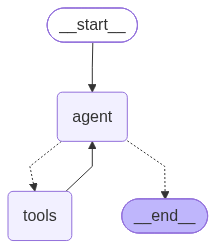

In [69]:
memory = MemorySaver()

graph_memory = create_react_agent(
    model=llm,
    tools=tools,
    prompt=prompt,
    # 대화 기록을 담아둘 비어 있는 메모리 객체를 연결한다.
    checkpointer=memory
)

display(Image(graph.get_graph().draw_mermaid_png()))

In [70]:
messages = [HumanMessage(content='스테이크 메뉴의 가격은 얼마인가요?')]
messages = graph_memory.invoke({'messages': messages}, config_3)

In [71]:
for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

스테이크 메뉴의 가격은 얼마인가요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_ZM9Lqb78CVB9fx9S7gx8MAd9)
 Call ID: call_ZM9Lqb78CVB9fx9S7gx8MAd9
  Args:
    query: 스테이크
================================= Tool Message =================================
Name: search_menu

1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.
================================== Ai Message ==================================

스테이크 메뉴의 가격은 다음과 같습니다:

1. **시그니처 스테이크**: ₩35,000
2. **안심 스테이크 샐러드**: ₩26,000

각 스테이크는 고유한 식재

In [72]:
messages = [HumanMessage(content='둘 중 저렴한 메뉴는 무엇인가요?')]
messages = graph_memory.invoke({'messages': messages}, config_3)

for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

스테이크 메뉴의 가격은 얼마인가요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_ZM9Lqb78CVB9fx9S7gx8MAd9)
 Call ID: call_ZM9Lqb78CVB9fx9S7gx8MAd9
  Args:
    query: 스테이크
================================= Tool Message =================================
Name: search_menu

1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.
================================== Ai Message ==================================

스테이크 메뉴의 가격은 다음과 같습니다:

1. **시그니처 스테이크**: ₩35,000
2. **안심 스테이크 샐러드**: ₩26,000

각 스테이크는 고유한 식재

In [73]:
config_4 = {'configurable': {'thread_id': str(uuid.uuid4())}}

In [74]:
messages = [HumanMessage(content='채식주의자를 위한 메뉴가 있나요?')]
messages = graph_memory.invoke({'messages': messages}, config_4)

for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

채식주의자를 위한 메뉴가 있나요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_oA2xUP0BVNxmHLXez9k2x2yV)
 Call ID: call_oA2xUP0BVNxmHLXez9k2x2yV
  Args:
    query: 채식주의자 메뉴
================================= Tool Message =================================
Name: search_menu

5. 가든 샐러드
    가격: ₩12,000
    주요 식재료: 유기농 믹스 그린, 체리 토마토, 오이, 당근, 발사믹 드레싱
    설명: 신선한 유기농 채소들로 구성된 건강한 샐러드입니다. 아삭한 식감의 믹스 그린에 달콤한 체리 토마토, 오이, 당근을 더해 다양한 맛과 식감을 즐길 수 있습니다. 특제 발사믹 드레싱이 채소 본연의 맛을 살려줍니다.

6. 해산물 파스타
    가격: ₩24,000
    주요 식재료: 링귀네 파스타, 새우, 홍합, 오징어, 토마토 소스
    설명: 알 덴테로 삶은 링귀네 파스타에 신선한 해산물을 듬뿍 올린 메뉴입니다. 토마토 소스의 산미와 해산물의 감칠맛이 조화를 이루며, 마늘과 올리브 오일로 풍미를 더했습니다. 파슬리를 뿌려 향긋한 맛을 더합니다.
================================== Ai Message ==================================

채식주의자를 위한 메뉴로는 "가든 샐러드"가 있습니다. 

- **가든 샐러드**
  - **가격**: ₩12,000
  - **주요 식재료**: 유기농 믹스 그린, 체리 토마토, 오이, 당근, 발사믹 드레싱
  

In [75]:
messages = [HumanMessage(content='시스니처 스테이크의 가격은 얼마인가요?')]
messages = graph_memory.invoke({'messages': messages}, config_3)

for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

스테이크 메뉴의 가격은 얼마인가요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_ZM9Lqb78CVB9fx9S7gx8MAd9)
 Call ID: call_ZM9Lqb78CVB9fx9S7gx8MAd9
  Args:
    query: 스테이크
================================= Tool Message =================================
Name: search_menu

1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

8. 안심 스테이크 샐러드
    가격: ₩26,000
    주요 식재료: 소고기 안심, 루꼴라, 체리 토마토, 발사믹 글레이즈
    설명: 부드러운 안심 스테이크를 얇게 슬라이스하여 신선한 루꼴라 위에 올린 메인 요리 샐러드입니다. 체리 토마토와 파마산 치즈 플레이크로 풍미를 더하고, 발사믹 글레이즈로 마무리하여 고기의 풍미를 한층 끌어올렸습니다.
================================== Ai Message ==================================

스테이크 메뉴의 가격은 다음과 같습니다:

1. **시그니처 스테이크**: ₩35,000
2. **안심 스테이크 샐러드**: ₩26,000

각 스테이크는 고유한 식재

In [76]:
messages = [HumanMessage(content='재료가 어떻게 되나요?')]
messages = graph_memory.invoke({'messages': messages}, config_4)

for message in messages['messages']:
    message.pretty_print()

================================ Human Message =================================

채식주의자를 위한 메뉴가 있나요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_oA2xUP0BVNxmHLXez9k2x2yV)
 Call ID: call_oA2xUP0BVNxmHLXez9k2x2yV
  Args:
    query: 채식주의자 메뉴
================================= Tool Message =================================
Name: search_menu

5. 가든 샐러드
    가격: ₩12,000
    주요 식재료: 유기농 믹스 그린, 체리 토마토, 오이, 당근, 발사믹 드레싱
    설명: 신선한 유기농 채소들로 구성된 건강한 샐러드입니다. 아삭한 식감의 믹스 그린에 달콤한 체리 토마토, 오이, 당근을 더해 다양한 맛과 식감을 즐길 수 있습니다. 특제 발사믹 드레싱이 채소 본연의 맛을 살려줍니다.

6. 해산물 파스타
    가격: ₩24,000
    주요 식재료: 링귀네 파스타, 새우, 홍합, 오징어, 토마토 소스
    설명: 알 덴테로 삶은 링귀네 파스타에 신선한 해산물을 듬뿍 올린 메뉴입니다. 토마토 소스의 산미와 해산물의 감칠맛이 조화를 이루며, 마늘과 올리브 오일로 풍미를 더했습니다. 파슬리를 뿌려 향긋한 맛을 더합니다.
================================== Ai Message ==================================

채식주의자를 위한 메뉴로는 "가든 샐러드"가 있습니다. 

- **가든 샐러드**
  - **가격**: ₩12,000
  - **주요 식재료**: 유기농 믹스 그린, 체리 토마토, 오이, 당근, 발사믹 드레싱
  

# 그라디오 챗봇 인터페이스 적용하기

In [77]:
import gradio as gr

챗봇에 사용할 LangGraph 초기화한다.

In [78]:
# 대화 내용을 저장할 메모리 공간을 만든다.
memory = MemorySaver()
# 대화 내용을 저장할 메모리 공간을 compile() 메소드에 넘겨서 그래프를 컴파일한다.
graph_memory = builder.compile(checkpointer=memory)

챗봇 인터페이스에 나타낼 추천 질문을 만든다.

In [79]:
example_question = [
    '스테이크 메뉴의 가격은 얼마인가요?',
    '채식주의자를 위한 메뉴가 있나요?',
    '파스타에 어울리는 음료는 무엇인가요?',
    '오늘의 스페셜 메뉴는 무엇인가요?'
]

챗봇이 사용자의 질문을 받아 LangGraph를 실행하고 답변을 처리하는 함수를 만든다.

In [84]:
# 사용자가 입력한 질문(message), 대화 기록(history), 챗봇의 고유 ID(thread_id)를 인수로 넘겨받아 문자열을 리턴하는 함수
def message_process(message: str, history: List[dict], thread_id: str) -> str:
    try:
        # 인수로 넘겨받은 챗봇의 고유 ID로 스레드(대화방)를 설정한다.
        config = {'configurable': {'thread_id': thread_id}}
        # 사용자가 입력한 질문을 LangGraph의 상태가 인식할 수 있게 HumanMessage 객체로 만든다.
        input_ = {'messages': [HumanMessage(content=message)]}
        # 사용자가 입력한 질문과 챗봇의 고유 ID로 그래프를 실행한다.
        result = graph_memory.invoke(input_, config)
        
        # 그래프 실행 결과는 딕셔너리 타입이므로 정상적으로 처리가 되면 'messages' 키가 존재한다.
        if 'messages' in result.keys():
            # 현재 스레드의 ID와 지금까지 누적된 모든 대화 내용을 출력해서 디버깅(로깅)을 출력한다.
            print(f'스레드 ID: {thread_id}')
            for message in result['messages']:
                message.pretty_print()
                
            # AI가 방금 새로 만들어낸 답변 메시지를 얻어온다. 전체 대화 리스트 중 맨 마지막 요소를 얻어온다.
            last_message = result['messages'][-1]
            # 답변 메시지가 AI가 보낸 메시지(AIMessage)가 맞다면, AI가 보낸 메시지에서 본문(content)만 리턴시킨다.
            if isinstance(last_message, AIMessage):
                return last_message.content
            # ===== if            
        # ===== if
        return '응답을 생성하지 못했습니다.'
    except Exception as e:
        print(f'에러 메시지: {str(e)}')
        return '죄송합니다. 응답을 생성하는 동안 오류가 발생했습니다. 다시 시도해 주세요.'

챗봇 시스템을 관리하는 클래스를 만든다.

In [85]:
class ChatBot:
    # 이 클래스의 객체가 처음 생성될 때 생성자 함수(__init__)를 이용해서 챗봇의 고유 ID를 무작위로 생성한다.
    def __init__(self):
        self.thread_id = str(uuid.uuid4())
    
    # 그라디오 챗봇 인터페이스에 연결할 메소드를 만든다. 이 메소드는 채팅을 치면 자동으로 호출되는 메소드이다.
    def chat(self, message: str, history: List[dict]) -> str:
        print(f'스레드 ID: {self.thread_id}')
        # message_process() 함수를 호출해서 질문을 전달하고 답변을 받아와서 리턴시킨다.
        response = message_process(message, history, self.thread_id)
        return response
    
# ChatBot 클래스 객체를 생성한다.
chatbot = ChatBot()

그라디오 라이브러리로 챗봇 인터페이스를 구현한다.

In [86]:
with gr.Blocks(theme=gr.themes.Citrus()) as demo:
    gr.ChatInterface(
        fn=chatbot.chat,
        title='레스토랑 메뉴 AI 어시스턴트',
        description='메뉴 정보, 추천 음식 관련 질문에 답변해드립니다.',
        examples=example_question
    )

In [87]:
demo.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


스레드 ID: 0ea43707-d511-4f13-b0a9-3e800f903918
스레드 ID: 0ea43707-d511-4f13-b0a9-3e800f903918
================================ Human Message =================================

오늘의 스페셜 메뉴는 무엇인가요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_dv21ATQp0yb55wmWOOwP2p95)
 Call ID: call_dv21ATQp0yb55wmWOOwP2p95
  Args:
    query: 스페셜 메뉴
================================= Tool Message =================================
Name: search_menu

1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

2. 트러플 리조또
    가격: ₩22,000
    주요 식재료: 이탈리아산 아르보리오 쌀, 블랙 트러플, 파르미지아노 레지아노 치즈
    설명: 크리미한 텍스처의 리조또에 고급 블랙 트러플을 듬뿍 얹어 풍부한 향과 맛을 즐길 수 있는 메뉴입니다. 24개월 숙성된 파르미지아노 레지아노 치즈를 사용하여 깊은 맛을 더했으며, 주문 즉시 조리하여 최상의 상태로 제공됩니다.
================================== Ai Message ===========================

C:\Users\enjoy\AppData\Local\Temp\ipykernel_9448\1768396498.py:6: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-tavily package and should be used instead. To use it run `pip install -U :class:`~langchain-tavily` and import as `from :class:`~langchain_tavily import TavilySearch``.
  tavily_search = TavilySearchResults(max_results=2)


스레드 ID: 0ea43707-d511-4f13-b0a9-3e800f903918
================================ Human Message =================================

오늘의 스페셜 메뉴는 무엇인가요?
================================== Ai Message ==================================
Tool Calls:
  search_menu (call_dv21ATQp0yb55wmWOOwP2p95)
 Call ID: call_dv21ATQp0yb55wmWOOwP2p95
  Args:
    query: 스페셜 메뉴
================================= Tool Message =================================
Name: search_menu

1. 시그니처 스테이크
    가격: ₩35,000
    주요 식재료: 최상급 한우 등심, 로즈메리 감자, 그릴드 아스파라거스
    설명: 셰프의 특제 시그니처 메뉴로, 21일간 건조 숙성한 최상급 한우 등심을 사용합니다. 미디엄 레어로 조리하여 육즙을 최대한 보존하며, 로즈메리 향의 감자와 아삭한 그릴드 아스파라거스가 곁들여집니다. 레드와인 소스와 함께 제공되어 풍부한 맛을 더합니다.

2. 트러플 리조또
    가격: ₩22,000
    주요 식재료: 이탈리아산 아르보리오 쌀, 블랙 트러플, 파르미지아노 레지아노 치즈
    설명: 크리미한 텍스처의 리조또에 고급 블랙 트러플을 듬뿍 얹어 풍부한 향과 맛을 즐길 수 있는 메뉴입니다. 24개월 숙성된 파르미지아노 레지아노 치즈를 사용하여 깊은 맛을 더했으며, 주문 즉시 조리하여 최상의 상태로 제공됩니다.
================================== Ai Message ==================================

오늘의 스페셜 메뉴는 다음과 같습니다:

1. **시그니처 스테이

In [88]:
demo.close()

Closing server running on port: 7861
